In [1]:
import pandas as pd

#load dataset
df = pd.read_csv("data/labeledTrainData.tsv", sep='\t')

#preview
df.head()

,id,sentiment,review
0,5814_8,1,With all this stuff going down at the moment w...
1,2381_9,1,"\The Classic War of the Worlds\"" by Timothy Hi..."
2,7759_3,0,The film starts with a manager (Nicholas Bell)...
3,3630_4,0,It must be assumed that those who praised this...
4,9495_8,1,Superbly trashy and wondrously unpretentious 8...


1. Get the stemmed data using the same process you did in Week 3.

In [2]:
import re
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer

stemmer = PorterStemmer()
stop_words = set(stopwords.words("english"))

def review_to_words(raw_review):

    #keeping only letters
    letters_only = re.sub("[^a-zA-Z]", " ", raw_review)

    #lowercase and split
    words = letters_only.lower().split()

    #removing stopwords
    meaningful_words = [w for w in words if w not in stop_words]

    #stemming
    stemmed_words = [stemmer.stem(w) for w in meaningful_words]

    return " ".join(stemmed_words)

In [3]:
#clean reviews
clean_reviews = []

for review in df["review"]:
    clean_reviews.append(review_to_words(review))

I cleaned each review by following the steps in the code above. I kept only letters, made them lowercase, removed stopwords and stemmed what was left.

2. Split this into a training and test set.

In [4]:
from sklearn.model_selection import train_test_split

X = clean_reviews
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

This step split the dataset into a training set and a test set with an 80/20 split. That way, the training data can be used to build the model while the testing data challenges the model to perform when it encounters unknown reviews.

3. Fit and apply the tf-idf vectorization to the training set.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X_train_tfidf = tfidf.fit_transform(X_train)

Vectorization converts the text reviews into numerical values. This allows machine learning models to use the information. Vectorization also attributes weight to different words based on their frequency in reviews.

4. Apply but DO NOT FIT the tf-idf vectorization to the test set (Why?).

In [6]:
#use transform() instead of fit_transform()

X_test_tfidf = tfidf.transform(X_test)

I use transform() instead of fit_transform because I want to avoid fitting the vectorizer on the test data. The reason for doing this is because doing so would allow information from the test set to impact the model, which would be data leakage.

5. Train a logistic regression using the training data.

In [7]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000)

6. Find the model accuracy on test set.

In [8]:
from sklearn.metrics import accuracy_score

y_pred = log_model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8828


The logistic regression model achieved an accuracy of 88%. This is a positive indication of the models performance, meaning it predicts positive and negative movie reviews.

7. Create a confusion matrix for the test set predictions.

In [9]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[2150  331]
 [ 255 2264]]


The confusion matrix shows number of correct and incorrect predictions for both positive and negative movie reviews. The majority of reviews were classified correctly, but because accuracy is 88% and not 100%, there are some errors.

8. Get the precision, recall, and F1-score for the test set predictions.

In [10]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.89      0.87      0.88      2481
           1       0.87      0.90      0.89      2519

    accuracy                           0.88      5000
   macro avg       0.88      0.88      0.88      5000
weighted avg       0.88      0.88      0.88      5000



9. Create a ROC curve for the test set.

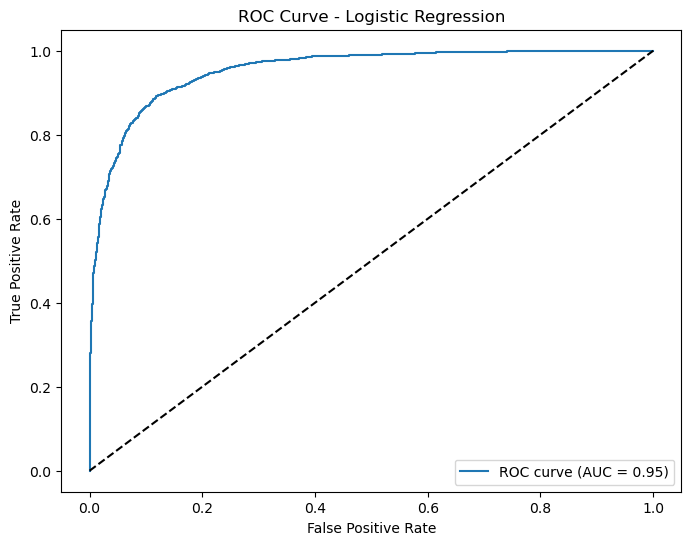

In [11]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

#probabilities
y_prob = log_model.predict_proba(X_test_tfidf)[:, 1]

#ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

#plotting ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label="ROC curve (AUC = %0.2f)" % roc_auc)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend(loc="lower right")
plt.show()

The ROC curve is close to the upper-left corner. This means the model performed well for classification. The AUC score of .95 also supports the notion that the model can separate positive and negative reviews consistently.

10. Pick another classification model you learned about this week and repeat steps (5) – (9).

    Model: Naive Bayes

In [12]:
#training naive bayes model
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

nb_pred = nb_model.predict(X_test_tfidf)

In [13]:
#finding model accuracy on test set
nb_accuracy = accuracy_score(y_test, nb_pred)

print("Naive Bayes Accuracy:", nb_accuracy)

Naive Bayes Accuracy: 0.8498


In [14]:
#confusion matrix
nb_cm = confusion_matrix(y_test, nb_pred)

print("Naive Bayes Confusion Matrix:")
print(nb_cm)

Naive Bayes Confusion Matrix:
[[2086  395]
 [ 356 2163]]


In [15]:
#precision, recall, f1 score
print(classification_report(y_test, nb_pred))

              precision    recall  f1-score   support

           0       0.85      0.84      0.85      2481
           1       0.85      0.86      0.85      2519

    accuracy                           0.85      5000
   macro avg       0.85      0.85      0.85      5000
weighted avg       0.85      0.85      0.85      5000



The classification report for Naive Bayes indicates a good performance similar to the Logistic Regression. However, its scores are lower across the board than the Logistic Regression.

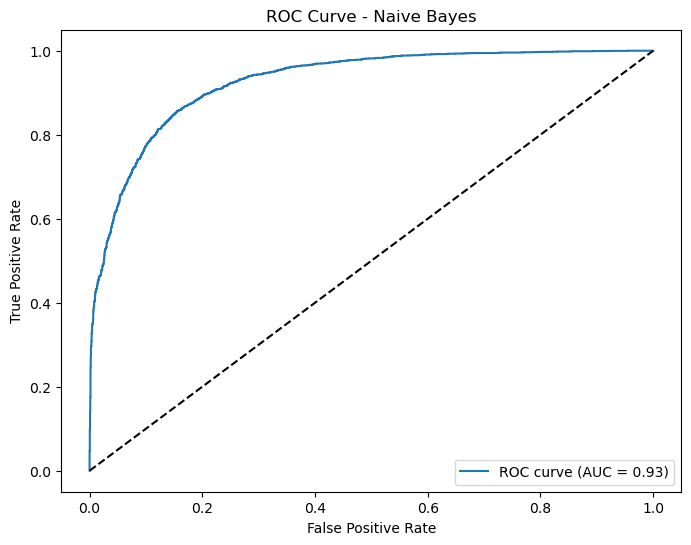

In [16]:
#ROC curve
nb_prob = nb_model.predict_proba(X_test_tfidf)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, nb_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label="ROC curve (AUC = %0.2f)" % roc_auc)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Naive Bayes")
plt.legend(loc="lower right")
plt.show()

Conclusions

Overall, logistic regression performed pretty well on the movie review dataset. The accuracy for sentiment classification was .88 for Logistic Regression, and .85 for Naive Bayes. TF-IDF vectorization improved accuracy by weighing the representation of more important words more highly. The ROC curve and AUC score for both models indicate strong classification performance between positive and negative reviews, with AUC scores of .95 for Logistic Regression and .93 for Naive Bayes. While both models performed well, Logistic Regression outscored Naive Bayes across the board when it came to precision, recall and f1 scores.